In [ ]:

!pip install -q kaggle tensorflow==2.15.0 scikit-learn matplotlib seaborn numpy pandas

print("✅ All libraries installed successfully!")
print("GPU Status:")
import tensorflow as tf
print("  TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print("  GPUs found:", gpus if gpus else "None — check runtime type!")

ERROR: Could not find a version that satisfies the requirement tensorflow==2.15.0 (from versions: 2.16.0rc0, 2.16.1, 2.16.2, 2.17.0rc0, 2.17.0rc1, 2.17.0, 2.17.1, 2.18.0rc0, 2.18.0rc1, 2.18.0rc2, 2.18.0, 2.18.1, 2.19.0rc0, 2.19.0, 2.19.1, 2.20.0rc0, 2.20.0, 2.21.0rc0, 2.21.0rc1, 2.21.0)
ERROR: No matching distribution found for tensorflow==2.15.0
✅ All libraries installed successfully!
GPU Status:
  TensorFlow: 2.20.0
  GPUs found: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, shutil, zipfile

# Create kaggle credentials folder
os.makedirs('/root/.kaggle', exist_ok=True)

# Copy kaggle.json from your Drive folder
shutil.copy('/content/drive/MyDrive/datasetkaggle/kaggle.json',
            '/root/.kaggle/kaggle.json')
os.chmod('/root/.kaggle/kaggle.json', 0o600)
print("✅ Kaggle credentials loaded from Drive!")

# Download dataset
ret = os.system('kaggle datasets download -d gunavenkatdoddi/eye-diseases-classification -p /content/')
if ret != 0:
    print("❌ Download failed — check your kaggle.json or internet connection.")
else:
    print("✅ Download complete!")

# Extract
zip_path = '/content/eye-diseases-classification.zip'
extract_path = '/content/eye_data/'
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(extract_path)
print("✅ Extraction complete!")

# ── Find DATA_ROOT (works regardless of nested folder structure) ──
DATA_ROOT = None
for root, dirs, _ in os.walk(extract_path):
    # Look for a folder that contains the 4 class subfolders
    class_folders = [d for d in dirs if d in
                     ['cataract', 'diabetic_retinopathy', 'glaucoma', 'normal',
                      'Cataract', 'Diabetic_Retinopathy', 'Glaucoma', 'Normal']]
    if len(class_folders) >= 3:
        DATA_ROOT = root
        break

if DATA_ROOT is None:
    print("❌ Could not find dataset folder. Check extraction output above.")
else:
    print(f"✅ Dataset root: {DATA_ROOT}")

# ── Count images per class ──
class_counts = {}
CLASS_DIRS = sorted(os.listdir(DATA_ROOT))
print("\n📂 Classes found:")
for cls in CLASS_DIRS:
    cls_path = os.path.join(DATA_ROOT, cls)
    if os.path.isdir(cls_path):
        imgs = [f for f in os.listdir(cls_path)
                if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        class_counts[cls] = len(imgs)
        print(f"   {cls}: {len(imgs)} images")

print(f"\n✅ Total images: {sum(class_counts.values())}")
print(f"✅ DATA_ROOT and class_counts are ready.\n")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Kaggle credentials loaded from Drive!
✅ Download complete!
✅ Extraction complete!
✅ Dataset root: /content/eye_data/dataset

📂 Classes found:
   cataract: 1038 images
   diabetic_retinopathy: 1098 images
   glaucoma: 1007 images
   normal: 1074 images

✅ Total images: 4217
✅ DATA_ROOT and class_counts are ready.



In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2, EfficientNetB0, DenseNet121
from tensorflow.keras.layers import (Dense, GlobalAveragePooling2D,
                                     Dropout, BatchNormalization)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (EarlyStopping, ReduceLROnPlateau,
                                        ModelCheckpoint)
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_score, recall_score,
                             f1_score, roc_curve, auc)
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.preprocessing import label_binarize

# ── Global settings ──────────────────────────────────────────
IMG_SIZE    = 224
BATCH_SIZE  = 16     # reduced from 32 — better gradient stability
EPOCHS      = 50     # increased from 25 — more time to learn
LR          = 1e-3   # increased from 1e-4 — faster initial learning
SEED        = 42
NUM_CLASSES = 4

np.random.seed(SEED)
tf.random.set_seed(SEED)

# Color palettes
PALETTE = {
    "MobileNetV2":    "#2196F3",
    "EfficientNetB0": "#4CAF50",
    "DenseNet121":    "#FF5722",
}
CLASS_COLORS = ["#E53935", "#8E24AA", "#1E88E5", "#43A047"]

print("✅ Parameters updated and set.")
print(f"   IMG_SIZE   = {IMG_SIZE}")
print(f"   BATCH_SIZE = {BATCH_SIZE}  (reduced for stability)")
print(f"   EPOCHS     = {EPOCHS}   (increased for better learning)")
print(f"   LR         = {LR}   (increased for faster start)")

✅ Parameters updated and set.
   IMG_SIZE   = 224
   BATCH_SIZE = 16  (reduced for stability)
   EPOCHS     = 50   (increased for better learning)
   LR         = 0.001   (increased for faster start)


In [ ]:
print(f"📂 Using DATA_ROOT: {DATA_ROOT}")

train_gen = ImageDataGenerator(
    rescale           = 1./255,
    rotation_range    = 20,
    width_shift_range = 0.15,
    height_shift_range= 0.15,
    horizontal_flip   = True,
    zoom_range        = 0.15,
    brightness_range  = [0.8, 1.2],
    fill_mode         = "nearest",
    validation_split  = 0.30
)

val_gen = ImageDataGenerator(
    rescale          = 1./255,
    validation_split = 0.30
)

train_data = train_gen.flow_from_directory(
    DATA_ROOT,
    target_size = (IMG_SIZE, IMG_SIZE),
    batch_size  = BATCH_SIZE,
    class_mode  = "categorical",
    subset      = "training",
    shuffle     = True,
    seed        = SEED
)

val_data = val_gen.flow_from_directory(
    DATA_ROOT,
    target_size = (IMG_SIZE, IMG_SIZE),
    batch_size  = BATCH_SIZE,
    class_mode  = "categorical",
    subset      = "validation",
    shuffle     = False,
    seed        = SEED
)

CLASS_NAMES = list(train_data.class_indices.keys())
print(f"\n✅ Data generators ready.")
print(f"   Class names  : {CLASS_NAMES}")
print(f"   Train samples: {train_data.samples}")
print(f"   Val   samples: {val_data.samples}")

📂 Using DATA_ROOT: /content/eye_data/dataset
Found 2953 images belonging to 4 classes.
Found 1264 images belonging to 4 classes.

✅ Data generators ready.
   Class names  : ['cataract', 'diabetic_retinopathy', 'glaucoma', 'normal']
   Train samples: 2953
   Val   samples: 1264


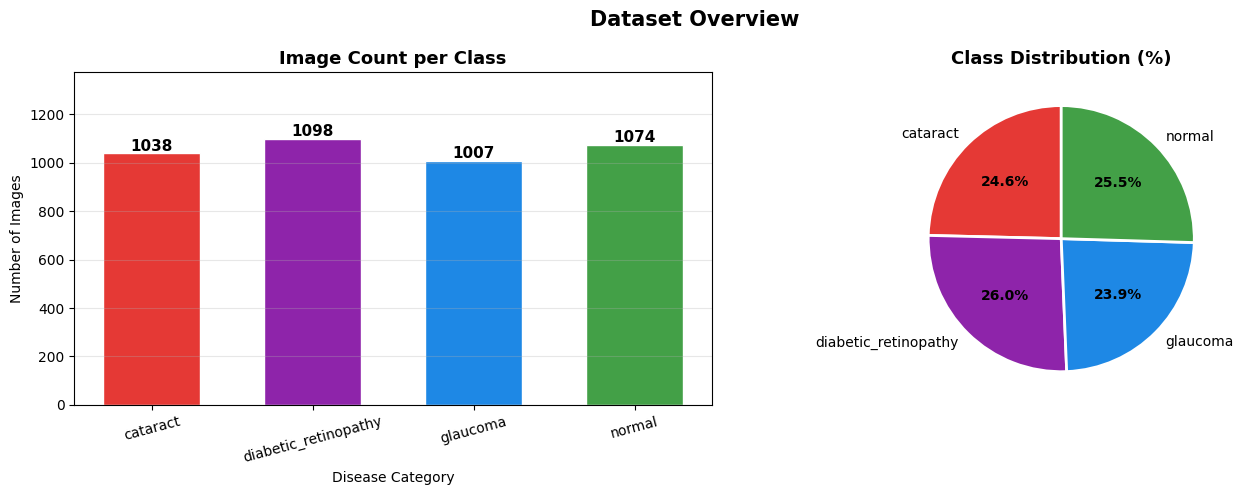

✅ Figure 1 saved.


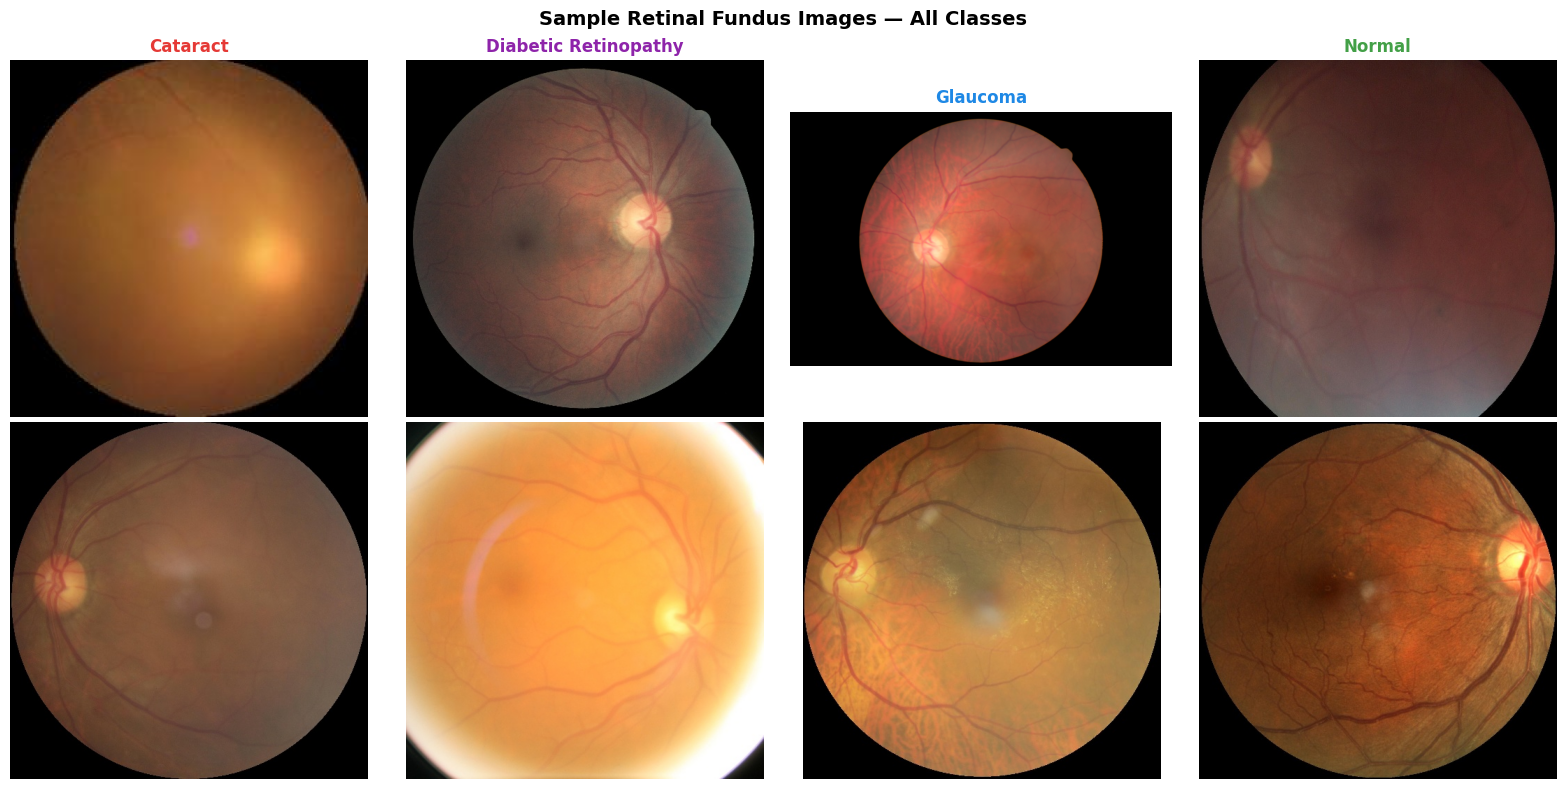

✅ Figure 2 saved.


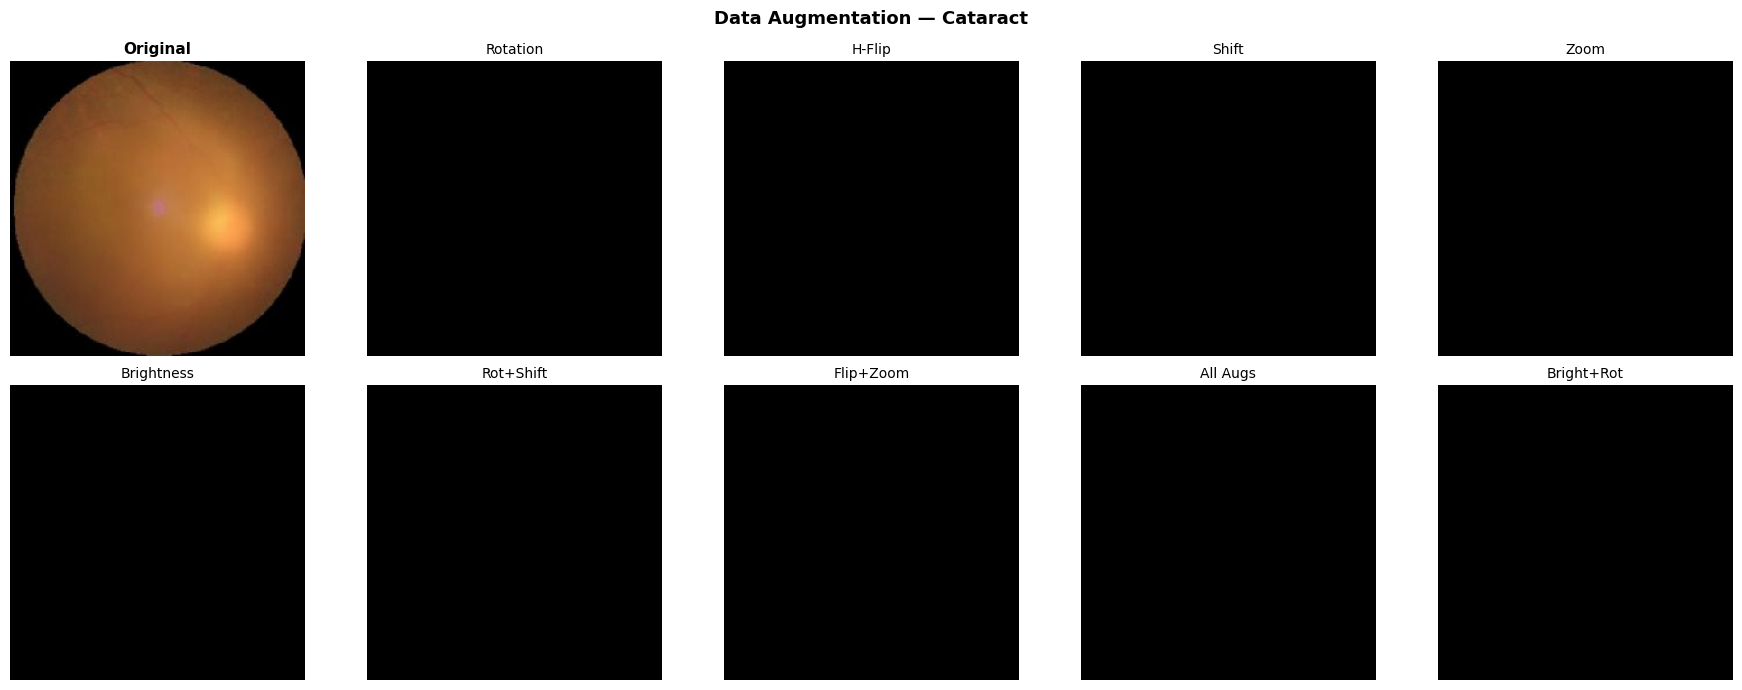

✅ Figure 3 saved.


In [ ]:
import os
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# ── 5a. Class distribution ────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Dataset Overview", fontsize=15, fontweight="bold")

counts = [class_counts.get(c, 0) for c in CLASS_NAMES]
bars = axes[0].bar(CLASS_NAMES, counts, color=CLASS_COLORS,
                   edgecolor="white", width=0.6)
axes[0].set_title("Image Count per Class", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Disease Category")
axes[0].set_ylabel("Number of Images")
axes[0].set_ylim(0, max(counts) * 1.25)
for bar, cnt in zip(bars, counts):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 10,
                 str(cnt), ha="center", fontweight="bold", fontsize=11)
axes[0].tick_params(axis="x", rotation=15)
axes[0].grid(axis="y", alpha=0.3)

wedges, texts, autotexts = axes[1].pie(
    counts, labels=CLASS_NAMES, colors=CLASS_COLORS,
    autopct="%1.1f%%", startangle=90,
    wedgeprops={"edgecolor": "white", "linewidth": 2}
)
for at in autotexts:
    at.set_fontsize(10)
    at.set_fontweight("bold")
axes[1].set_title("Class Distribution (%)", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.savefig("/content/01_class_distribution.png", dpi=120, bbox_inches="tight")
plt.show()
print("✅ Figure 1 saved.")

# ── 5b. Sample images ────────────────────────────────────────
fig, axes = plt.subplots(2, NUM_CLASSES, figsize=(16, 8))
fig.suptitle("Sample Retinal Fundus Images — All Classes",
             fontsize=14, fontweight="bold")
for col, (cls, color) in enumerate(zip(CLASS_NAMES, CLASS_COLORS)):
    cls_path = os.path.join(DATA_ROOT, cls)
    imgs = [f for f in os.listdir(cls_path)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    for row in range(2):
        img = plt.imread(os.path.join(cls_path, imgs[row]))
        axes[row, col].imshow(img)
        axes[row, col].axis("off")
        if row == 0:
            axes[row, col].set_title(
                cls.replace("_", " ").title(),
                fontsize=12, fontweight="bold", color=color
            )
plt.tight_layout()
plt.savefig("/content/02_sample_images.png", dpi=120, bbox_inches="tight")
plt.show()
print("✅ Figure 2 saved.")

# ── 5c. Augmentation showcase ─────────────────────────────────
aug_demo = ImageDataGenerator(
    rotation_range=20, width_shift_range=0.15,
    height_shift_range=0.15, horizontal_flip=True,
    zoom_range=0.15, brightness_range=[0.7, 1.3]
)
sample_cls  = CLASS_NAMES[0]
sample_file = [f for f in os.listdir(os.path.join(DATA_ROOT, sample_cls))
               if f.lower().endswith(('.jpg', '.jpeg', '.png'))][0]
sample_img  = load_img(os.path.join(DATA_ROOT, sample_cls, sample_file),
                       target_size=(IMG_SIZE, IMG_SIZE))
sample_arr  = img_to_array(sample_img) / 255.0

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
fig.suptitle(f"Data Augmentation — {sample_cls.replace('_',' ').title()}",
             fontsize=13, fontweight="bold")
axes[0, 0].imshow(sample_arr)
axes[0, 0].set_title("Original", fontsize=11, fontweight="bold")
axes[0, 0].axis("off")

aug_labels = ["Rotation", "H-Flip", "Shift", "Zoom", "Brightness",
              "Rot+Shift", "Flip+Zoom", "All Augs", "Bright+Rot"]
it = aug_demo.flow(sample_arr[np.newaxis], batch_size=1)
for idx in range(1, 10):
    row, col = divmod(idx, 5)
    aug_img = next(it)[0]
    axes[row, col].imshow(np.clip(aug_img, 0, 1))
    axes[row, col].set_title(aug_labels[idx-1], fontsize=10)
    axes[row, col].axis("off")

plt.tight_layout()
plt.savefig("/content/03_augmentation_showcase.png", dpi=120, bbox_inches="tight")
plt.show()
print("✅ Figure 3 saved.")

In [ ]:
def build_cnn_model(base_fn, model_name):
    base = base_fn(weights="imagenet", include_top=False,
                   input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False

    x = GlobalAveragePooling2D()(base.output)
    x = BatchNormalization()(x)
    x = Dense(512, activation="relu")(x)
    x = Dropout(0.5)(x)
    x = Dense(256, activation="relu")(x)
    x = Dropout(0.3)(x)
    out = Dense(NUM_CLASSES, activation="softmax")(x)

    model = Model(inputs=base.input, outputs=out, name=model_name)
    model.compile(
        optimizer=Adam(learning_rate=LR),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

print("✅ Model builder defined.")
print("\n📋 Architecture Summary:")
arch_df = pd.DataFrame({
    "Model":      ["MobileNetV2", "EfficientNetB0", "DenseNet121"],
    "Design":     ["Depthwise Separable", "Compound Scaling", "Dense Connectivity"],
    "Strength":   ["Fastest / Lightest", "Best Accuracy-Efficiency", "Strong Generalization"],
    "Best For":   ["Mobile / Edge Devices", "General High Accuracy", "High-Resource Tasks"],
})
print(arch_df.to_string(index=False))


✅ Model builder defined.

📋 Architecture Summary:
         Model              Design                 Strength              Best For
   MobileNetV2 Depthwise Separable       Fastest / Lightest Mobile / Edge Devices
EfficientNetB0    Compound Scaling Best Accuracy-Efficiency General High Accuracy
   DenseNet121  Dense Connectivity    Strong Generalization   High-Resource Tasks


In [ ]:
def train_model(model, model_name):
    print(f"\n{'='*60}")
    print(f"  TRAINING: {model_name}")
    print(f"  Parameters: {model.count_params():,}")
    print(f"{'='*60}")

    callbacks = [
        EarlyStopping(
            monitor="val_loss",
            patience=10,                  # was 6 — now gives more time
            restore_best_weights=True,
            verbose=1
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.3,                   # was 0.5 — more aggressive reduction
            patience=5,                   # was 3 — more patience before reducing
            min_lr=1e-7,
            verbose=1
        ),
        ModelCheckpoint(
            f"/content/{model_name}_best.h5",
            monitor="val_accuracy",
            save_best_only=True,
            verbose=0
        )
    ]

    history = model.fit(
        train_data,
        epochs=EPOCHS,
        validation_data=val_data,
        callbacks=callbacks,
        verbose=1
    )
    print(f"\n✅ {model_name} training complete.")
    return history

In [ ]:
def evaluate_model(model, model_name):
    val_data.reset()
    preds  = model.predict(val_data, verbose=0)
    y_pred = np.argmax(preds, axis=1)
    y_true = val_data.classes[:len(y_pred)]
    y_score = preds

    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average="weighted", zero_division=0)
    rec  = recall_score(y_true, y_pred, average="weighted", zero_division=0)
    f1   = f1_score(y_true, y_pred, average="weighted", zero_division=0)
    per_class = classification_report(
        y_true, y_pred, target_names=CLASS_NAMES,
        output_dict=True, zero_division=0
    )

    print(f"\n─── {model_name} ───────────────────────────────────────")
    print(f"  Accuracy : {acc:.4f}")
    print(f"  Precision: {prec:.4f}")
    print(f"  Recall   : {rec:.4f}")
    print(f"  F1-Score : {f1:.4f}")
    print(f"\n{classification_report(y_true, y_pred, target_names=CLASS_NAMES, zero_division=0)}")

    return {
        "name":      model_name,
        "accuracy":  acc,
        "precision": prec,
        "recall":    rec,
        "f1_score":  f1,
        "y_true":    y_true,
        "y_pred":    y_pred,
        "y_score":   y_score,
        "per_class": per_class,
        "cm":        confusion_matrix(y_true, y_pred),
    }

In [ ]:
import os
DRIVE_SAVE = "/content/drive/MyDrive/datasetkaggle/results/"
os.makedirs(DRIVE_SAVE, exist_ok=True)

# ── MobileNetV2 ──────────────────────────────────────────────
mobilenet_model = build_cnn_model(MobileNetV2, "MobileNetV2")
mobilenet_hist  = train_model(mobilenet_model, "MobileNetV2")
mobilenet_res   = evaluate_model(mobilenet_model, "MobileNetV2")
mobilenet_model.save(DRIVE_SAVE + "mobilenet_model.h5")
print("✅ MobileNetV2 saved to Drive!")

# ── EfficientNetB0 ───────────────────────────────────────────
efficientnet_model = build_cnn_model(EfficientNetB0, "EfficientNetB0")
efficientnet_hist  = train_model(efficientnet_model, "EfficientNetB0")
efficientnet_res   = evaluate_model(efficientnet_model, "EfficientNetB0")
efficientnet_model.save(DRIVE_SAVE + "efficientnet_model.h5")
print("✅ EfficientNetB0 saved to Drive!")

# ── DenseNet121 ──────────────────────────────────────────────
densenet_model = build_cnn_model(DenseNet121, "DenseNet121")
densenet_hist  = train_model(densenet_model, "DenseNet121")
densenet_res   = evaluate_model(densenet_model, "DenseNet121")
densenet_model.save(DRIVE_SAVE + "densenet_model.h5")
print("✅ DenseNet121 saved to Drive!")

# ── Bundle results ───────────────────────────────────────────
results = [mobilenet_res, efficientnet_res, densenet_res]
histories = {
    "MobileNetV2":    mobilenet_hist,
    "EfficientNetB0": efficientnet_hist,
    "DenseNet121":    densenet_hist,
}
print("\n✅ All three models trained, evaluated and saved to Drive!")
print(f"   Location: My Drive → datasetkaggle → results")


  TRAINING: MobileNetV2
  Parameters: 3,051,332
Epoch 1/50
185/185 ━━━━━━━━━━━━━━━━━━━━ 0s 362ms/step - accuracy: 0.6544 - loss: 1.0293

185/185 ━━━━━━━━━━━━━━━━━━━━ 89s 418ms/step - accuracy: 0.7237 - loss: 0.8280 - val_accuracy: 0.4597 - val_loss: 2.2646 - learning_rate: 0.0010
Epoch 2/50
185/185 ━━━━━━━━━━━━━━━━━━━━ 65s 350ms/step - accuracy: 0.7897 - loss: 0.5631 - val_accuracy: 0.4375 - val_loss: 3.4111 - learning_rate: 0.0010
Epoch 3/50
185/185 ━━━━━━━━━━━━━━━━━━━━ 66s 355ms/step - accuracy: 0.8239 - loss: 0.4400 - val_accuracy: 0.4169 - val_loss: 4.3764 - learning_rate: 0.0010
Epoch 4/50
185/185 ━━━━━━━━━━━━━━━━━━━━ 66s 357ms/step - accuracy: 0.8398 - loss: 0.4297 - val_accuracy: 0.4573 - val_loss: 3.4099 - learning_rate: 0.0010
Epoch 5/50
185/185 ━━━━━━━━━━━━━━━━━━━━ 65s 351ms/step - accuracy: 0.8381 - loss: 0.4238 - val_accuracy: 0.4557 - val_loss: 4.1628 - learning_rate: 0.0010
Epoch 6/50
185/185 ━━━━━━━━━━━━━━━━━━━━ 0s 338ms/step - accuracy: 0.8500 - loss: 0.3779
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
185/185 ━━━━━━━━━━━━━━━━━━━━ 66s 358ms/step - accuracy: 0.8391 - loss: 0

185/185 ━━━━━━━━━━━━━━━━━━━━ 68s 368ms/step - accuracy: 0.8791 - loss: 0.3008 - val_accuracy: 0.4604 - val_loss: 5.8165 - learning_rate: 3.0000e-04
Epoch 10/50
185/185 ━━━━━━━━━━━━━━━━━━━━ 67s 362ms/step - accuracy: 0.8906 - loss: 0.3000 - val_accuracy: 0.4557 - val_loss: 5.1840 - learning_rate: 3.0000e-04
Epoch 11/50
185/185 ━━━━━━━━━━━━━━━━━━━━ 0s 330ms/step - accuracy: 0.8993 - loss: 0.2449
Epoch 11: ReduceLROnPlateau reducing learning rate to 9.000000427477062e-05.
185/185 ━━━━━━━━━━━━━━━━━━━━ 66s 358ms/step - accuracy: 0.8910 - loss: 0.2561 - val_accuracy: 0.4328 - val_loss: 5.7675 - learning_rate: 3.0000e-04
Epoch 11: early stopping
Restoring model weights from the end of the best epoch: 1.

✅ MobileNetV2 training complete.



─── MobileNetV2 ───────────────────────────────────────
  Accuracy : 0.4597
  Precision: 0.7412
  Recall   : 0.4597
  F1-Score : 0.3714

                      precision    recall  f1-score   support

            cataract       1.00      0.12      0.22       311
diabetic_retinopathy       0.67      0.88      0.76       329
            glaucoma       1.00      0.01      0.02       302
              normal       0.32      0.78      0.45       322

            accuracy                           0.46      1264
           macro avg       0.75      0.45      0.36      1264
        weighted avg       0.74      0.46      0.37      1264

✅ MobileNetV2 saved to Drive!

  TRAINING: EfficientNetB0
  Parameters: 4,842,919
Epoch 1/50
185/185 ━━━━━━━━━━━━━━━━━━━━ 0s 390ms/step - accuracy: 0.2357 - loss: 1.9580

185/185 ━━━━━━━━━━━━━━━━━━━━ 108s 458ms/step - accuracy: 0.2418 - loss: 1.8446 - val_accuracy: 0.2460 - val_loss: 1.3867 - learning_rate: 0.0010
Epoch 2/50
185/185 ━━━━━━━━━━━━━━━━━━━━ 0s 331ms/step - accuracy: 0.2442 - loss: 1.5201

...


─── EfficientNetB0 ───────────────────────────────────────
  Accuracy : 0.2603
  Precision: 0.0677
  Recall   : 0.2603
  F1-Score : 0.1075

                      precision    recall  f1-score   support

            cataract       0.00      0.00      0.00       311
diabetic_retinopathy       0.26      1.00      0.41       329
            glaucoma       0.00      0.00      0.00       302
              normal       0.00      0.00      0.00       322

            accuracy                           0.26      1264
           macro avg       0.07      0.25      0.10      1264
        weighted avg       0.07      0.26      0.11      1264

✅ EfficientNetB0 saved to Drive!

  TRAINING: DenseNet121
  Parameters: 7,698,756
Epoch 1/50
185/185 ━━━━━━━━━━━━━━━━━━━━ 0s 418ms/step - accuracy: 0.7005 - loss: 0.7944

185/185 ━━━━━━━━━━━━━━━━━━━━ 122s 519ms/step - accuracy: 0.7741 - loss: 0.6032 - val_accuracy: 0.4201 - val_loss: 2.1159 - learning_rate: 0.0010
Epoch 2/50
185/185 ━━━━━━━━━━━━━━━━━━━━ 0s 350ms/step - accuracy: 0.8303 - loss: 0.4426

185/185 ━━━━━━━━━━━━━━━━━━━━ 69s 375ms/step - accuracy: 0.8483 - loss: 0.4082 - val_accuracy: 0.4533 - val_loss: 3.8408 - learning_rate: 0.0010
Epoch 3/50
185/185 ━━━━━━━━━━━━━━━━━━━━ 71s 384ms/step - accuracy: 0.8689 - loss: 0.3355 - val_accuracy: 0.4462 - val_loss: 4.5184 - learning_rate: 0.0010
Epoch 4/50
185/185 ━━━━━━━━━━━━━━━━━━━━ 69s 371ms/step - accuracy: 0.8764 - loss: 0.3418 - val_accuracy: 0.4114 - val_loss: 3.7478 - learning_rate: 0.0010
Epoch 5/50
185/185 ━━━━━━━━━━━━━━━━━━━━ 0s 348ms/step - accuracy: 0.8786 - loss: 0.3009

185/185 ━━━━━━━━━━━━━━━━━━━━ 70s 380ms/step - accuracy: 0.8811 - loss: 0.2962 - val_accuracy: 0.4691 - val_loss: 4.8050 - learning_rate: 0.0010
Epoch 6/50
185/185 ━━━━━━━━━━━━━━━━━━━━ 0s 346ms/step - accuracy: 0.8867 - loss: 0.2805
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
185/185 ━━━━━━━━━━━━━━━━━━━━ 74s 402ms/step - accuracy: 0.8899 - loss: 0.2935 - val_accuracy: 0.4391 - val_loss: 7.0888 - learning_rate: 0.0010
Epoch 7/50
185/185 ━━━━━━━━━━━━━━━━━━━━ 70s 376ms/step - accuracy: 0.9133 - loss: 0.2231 - val_accuracy: 0.3979 - val_loss: 7.2338 - learning_rate: 3.0000e-04
Epoch 8/50
185/185 ━━━━━━━━━━━━━━━━━━━━ 69s 374ms/step - accuracy: 0.9180 - loss: 0.2202 - val_accuracy: 0.4161 - val_loss: 6.9916 - learning_rate: 3.0000e-04
Epoch 9/50
185/185 ━━━━━━━━━━━━━━━━━━━━ 74s 403ms/step - accuracy: 0.9262 - loss: 0.1964 - val_accuracy: 0.4138 - val_loss: 6.7720 - learning_rate: 3.0000e-04
Epoch 10/50
185/185 ━━━━━━━━━━━━━━━━━━━━ 70s 376ms/step - accuracy: 0.9


─── DenseNet121 ───────────────────────────────────────
  Accuracy : 0.4201
  Precision: 0.7402
  Recall   : 0.4201
  F1-Score : 0.3401

                      precision    recall  f1-score   support

            cataract       1.00      0.05      0.10       311
diabetic_retinopathy       0.91      0.59      0.72       329
            glaucoma       0.75      0.02      0.04       302
              normal       0.31      0.97      0.46       322

            accuracy                           0.42      1264
           macro avg       0.74      0.41      0.33      1264
        weighted avg       0.74      0.42      0.34      1264

✅ DenseNet121 saved to Drive!

✅ All three models trained, evaluated and saved to Drive!
   Location: My Drive → datasetkaggle → results


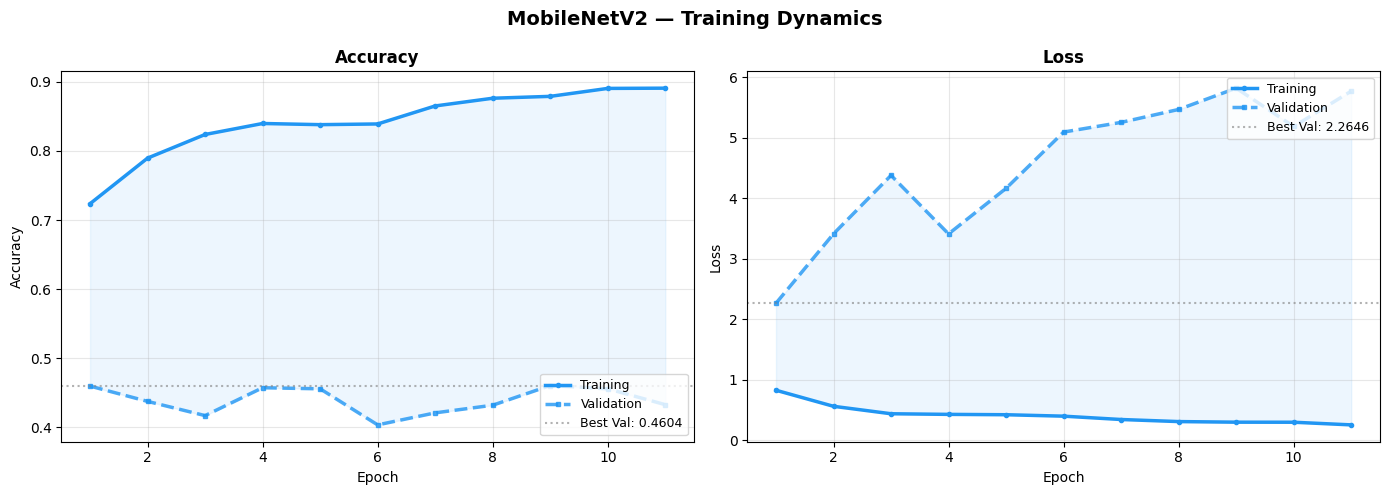

✅ Saved: 04_MobileNetV2_curves.png


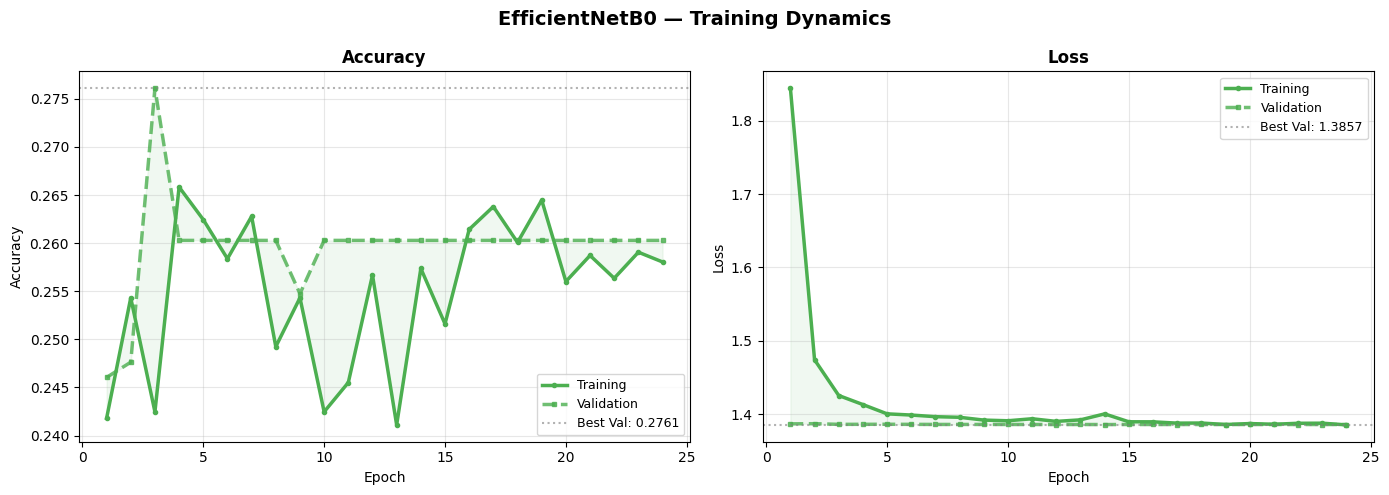

✅ Saved: 04_EfficientNetB0_curves.png


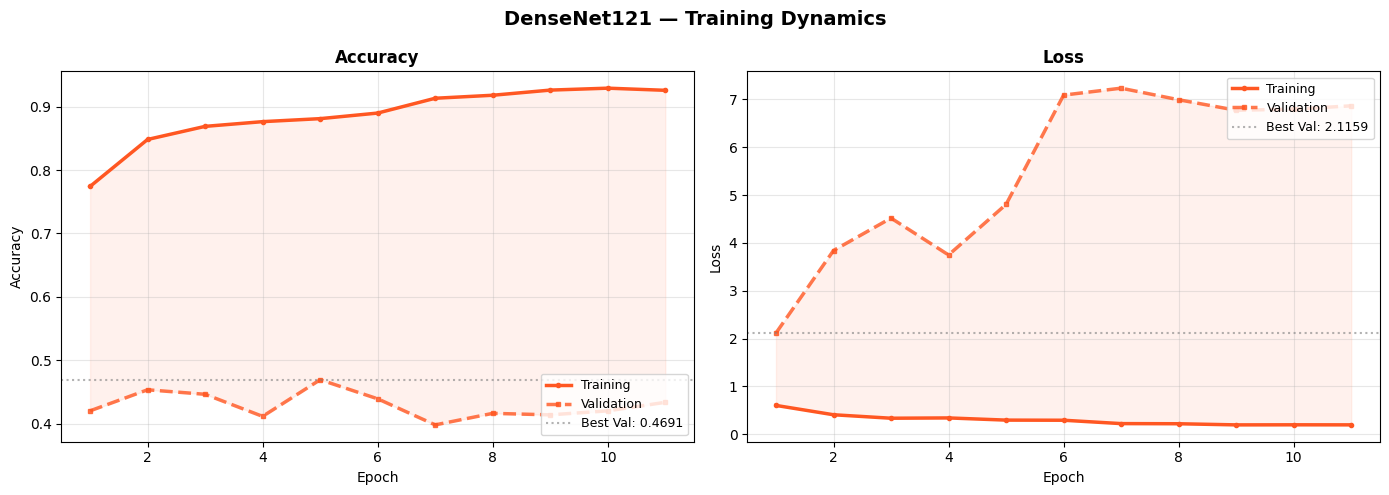

✅ Saved: 04_DenseNet121_curves.png


In [ ]:
def plot_training_curves(history, model_name, color):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(f"{model_name} — Training Dynamics",
                 fontsize=14, fontweight="bold")
    ep = range(1, len(history.history["accuracy"]) + 1)

    for ax, metric, val_metric, ylabel, loc in [
        (axes[0], "accuracy",    "val_accuracy", "Accuracy",  "lower right"),
        (axes[1], "loss",        "val_loss",     "Loss",      "upper right"),
    ]:
        ax.plot(ep, history.history[metric],
                color=color, linewidth=2.5, label="Training",
                marker="o", markersize=3)
        ax.plot(ep, history.history[val_metric],
                color=color, linewidth=2.5, linestyle="--",
                label="Validation", marker="s", markersize=3, alpha=0.8)
        ax.fill_between(ep,
                        history.history[metric],
                        history.history[val_metric],
                        alpha=0.08, color=color)
        best = (max if metric=="accuracy" else min)(history.history[val_metric])
        ax.axhline(best, color="gray", linestyle=":", alpha=0.6,
                   label=f"Best Val: {best:.4f}")
        ax.set_title(ylabel, fontsize=12, fontweight="bold")
        ax.set_xlabel("Epoch")
        ax.set_ylabel(ylabel)
        ax.legend(fontsize=9, loc=loc)
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(f"/content/04_{model_name}_curves.png", dpi=120, bbox_inches="tight")
    plt.show()
    print(f"✅ Saved: 04_{model_name}_curves.png")

for name, hist in histories.items():
    plot_training_curves(hist, name, PALETTE[name])

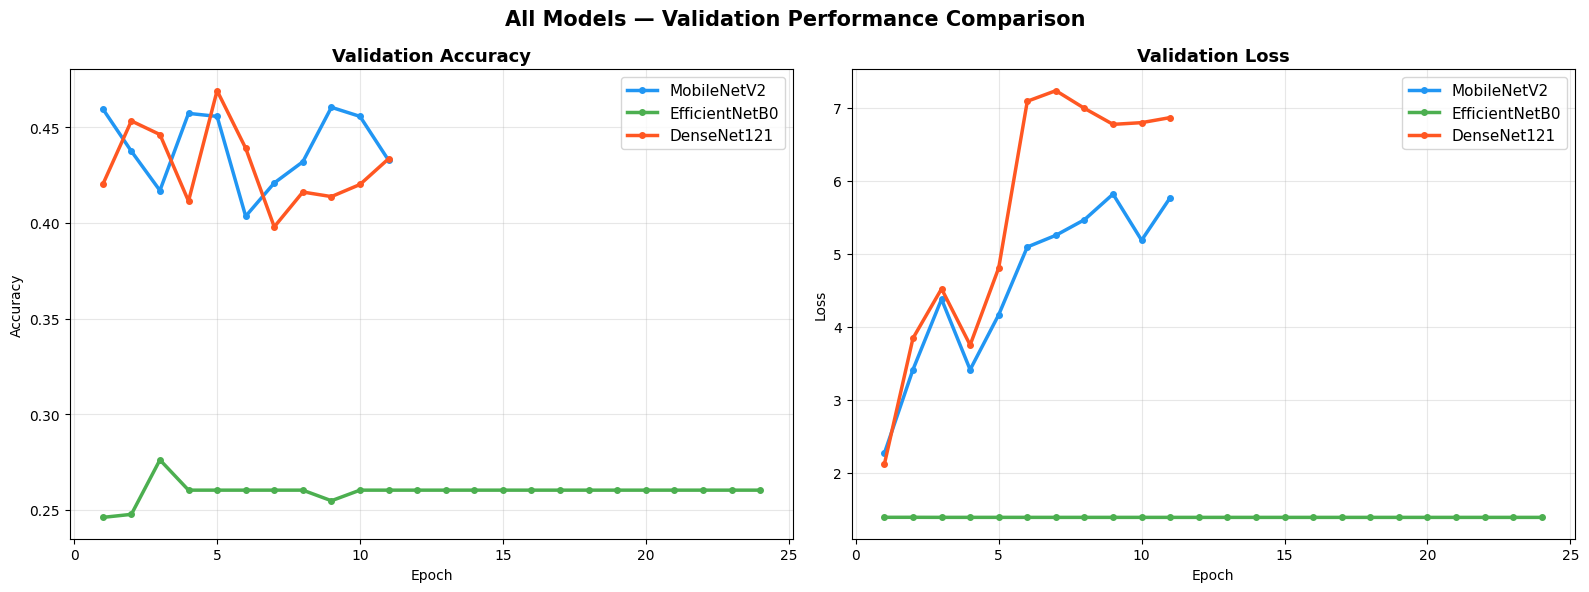

✅ Figure 5 saved.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("All Models — Validation Performance Comparison",
             fontsize=15, fontweight="bold")

for name, hist in histories.items():
    color = PALETTE[name]
    ep    = range(1, len(hist.history["val_accuracy"]) + 1)
    axes[0].plot(ep, hist.history["val_accuracy"],
                 color=color, linewidth=2.5, label=name,
                 marker="o", markersize=4)
    axes[1].plot(ep, hist.history["val_loss"],
                 color=color, linewidth=2.5, label=name,
                 marker="o", markersize=4)

for ax, title, ylabel in [
    (axes[0], "Validation Accuracy", "Accuracy"),
    (axes[1], "Validation Loss",     "Loss"),
]:
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=11)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("/content/05_combined_curves.png", dpi=120, bbox_inches="tight")
plt.show()
print("✅ Figure 5 saved.")



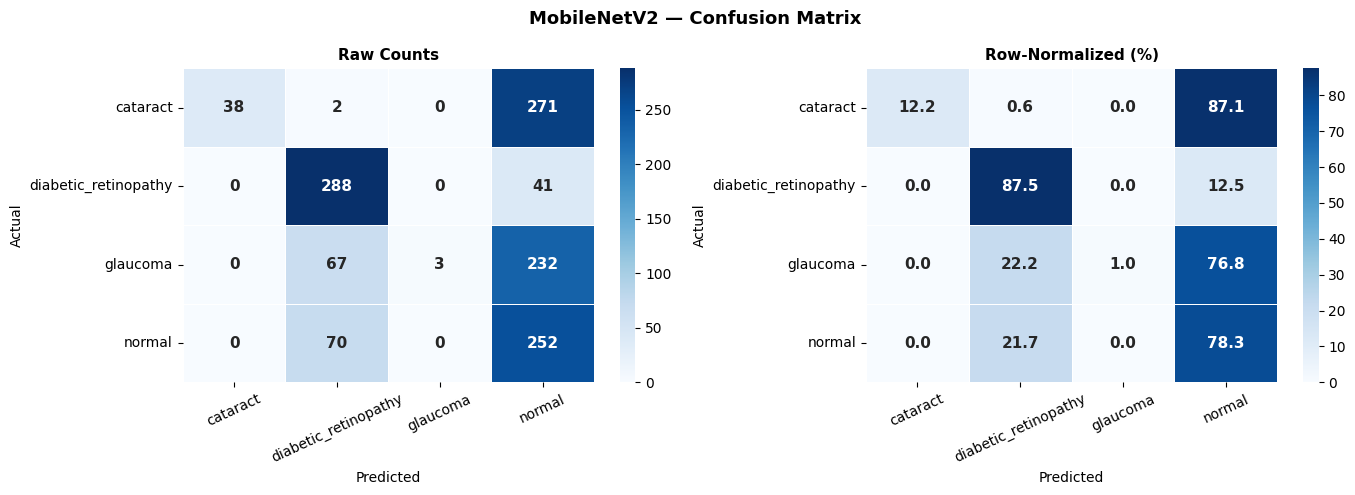

✅ Saved: 06_MobileNetV2_cm.png


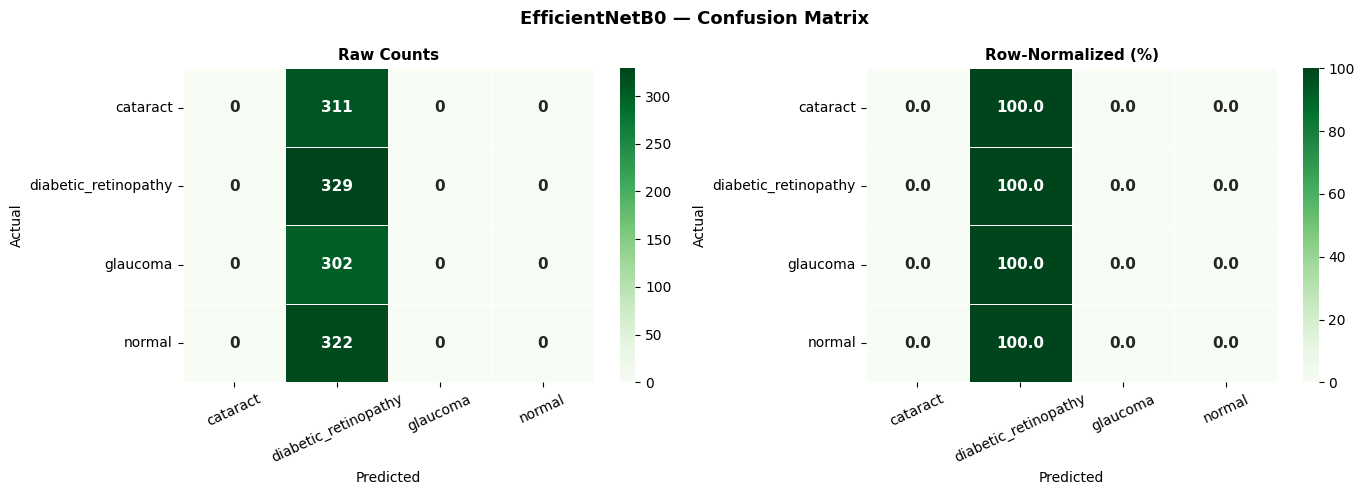

✅ Saved: 06_EfficientNetB0_cm.png


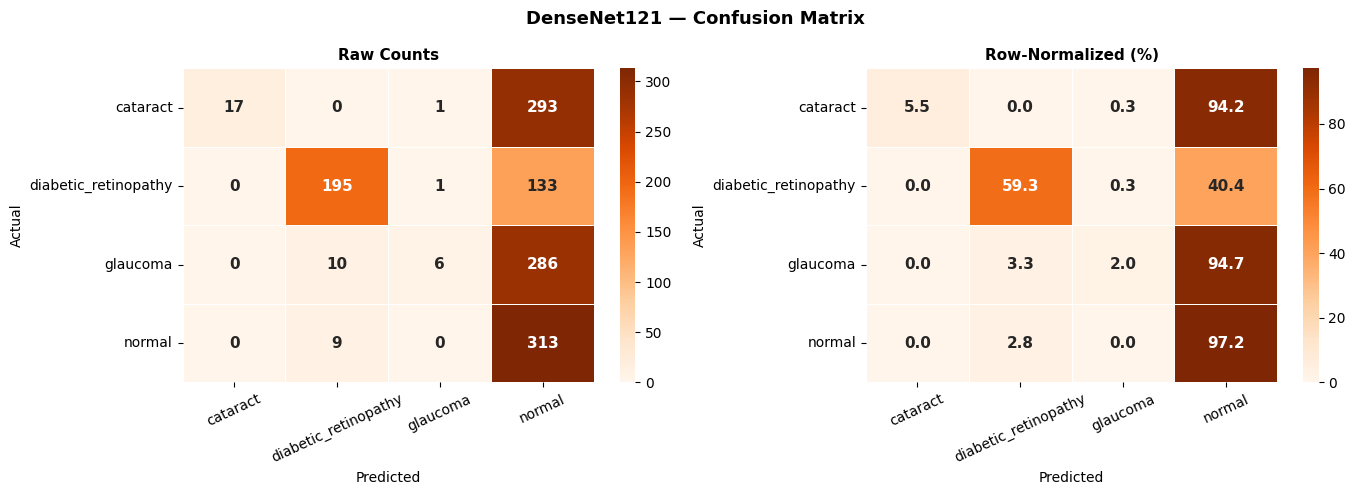

✅ Saved: 06_DenseNet121_cm.png


In [ ]:
def plot_confusion_matrix(res, cmap):
    cm     = res["cm"]
    cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(f"{res['name']} — Confusion Matrix",
                 fontsize=13, fontweight="bold")

    for ax, data, fmt, title in [
        (axes[0], cm,     "d",    "Raw Counts"),
        (axes[1], cm_pct, ".1f",  "Row-Normalized (%)"),
    ]:
        sns.heatmap(data, annot=True, fmt=fmt, cmap=cmap, ax=ax,
                    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                    linewidths=0.5, linecolor="white",
                    annot_kws={"size": 11, "weight": "bold"})
        ax.set_title(title, fontsize=11, fontweight="bold")
        ax.set_xlabel("Predicted", fontsize=10)
        ax.set_ylabel("Actual", fontsize=10)
        ax.tick_params(axis="x", rotation=25)
        ax.tick_params(axis="y", rotation=0)

    plt.tight_layout()
    plt.savefig(f"/content/06_{res['name']}_cm.png", dpi=120, bbox_inches="tight")
    plt.show()
    print(f"✅ Saved: 06_{res['name']}_cm.png")

for res, cmap in zip(results, ["Blues", "Greens", "Oranges"]):
    plot_confusion_matrix(res, cmap)

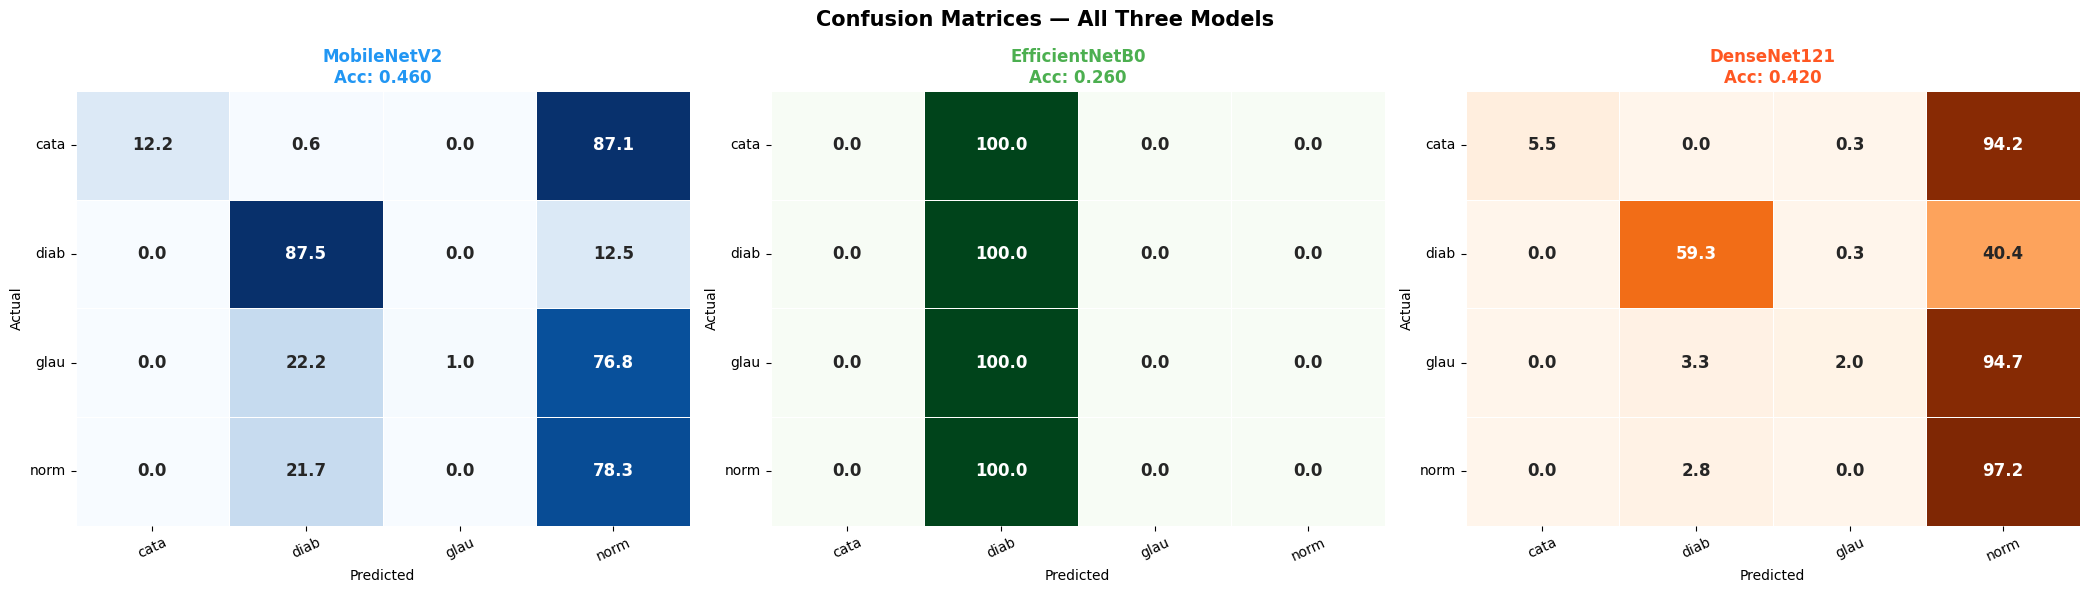

✅ Figure 7 saved.


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(21, 6))
fig.suptitle("Confusion Matrices — All Three Models",
             fontsize=15, fontweight="bold")

for ax, res, cmap in zip(axes, results, ["Blues", "Greens", "Oranges"]):
    cm_pct = res["cm"].astype(float) / res["cm"].sum(axis=1, keepdims=True) * 100
    sns.heatmap(cm_pct, annot=True, fmt=".1f", cmap=cmap, ax=ax,
                xticklabels=[c[:4] for c in CLASS_NAMES],
                yticklabels=[c[:4] for c in CLASS_NAMES],
                cbar=False, linewidths=0.5, linecolor="white",
                annot_kws={"size": 12, "weight": "bold"})
    ax.set_title(f"{res['name']}\nAcc: {res['accuracy']:.3f}",
                 fontsize=12, fontweight="bold",
                 color=PALETTE[res['name']])
    ax.set_xlabel("Predicted", fontsize=10)
    ax.set_ylabel("Actual", fontsize=10)
    ax.tick_params(axis="x", rotation=25)
    ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.savefig("/content/07_all_cm.png", dpi=120, bbox_inches="tight")
plt.show()
print("✅ Figure 7 saved.")

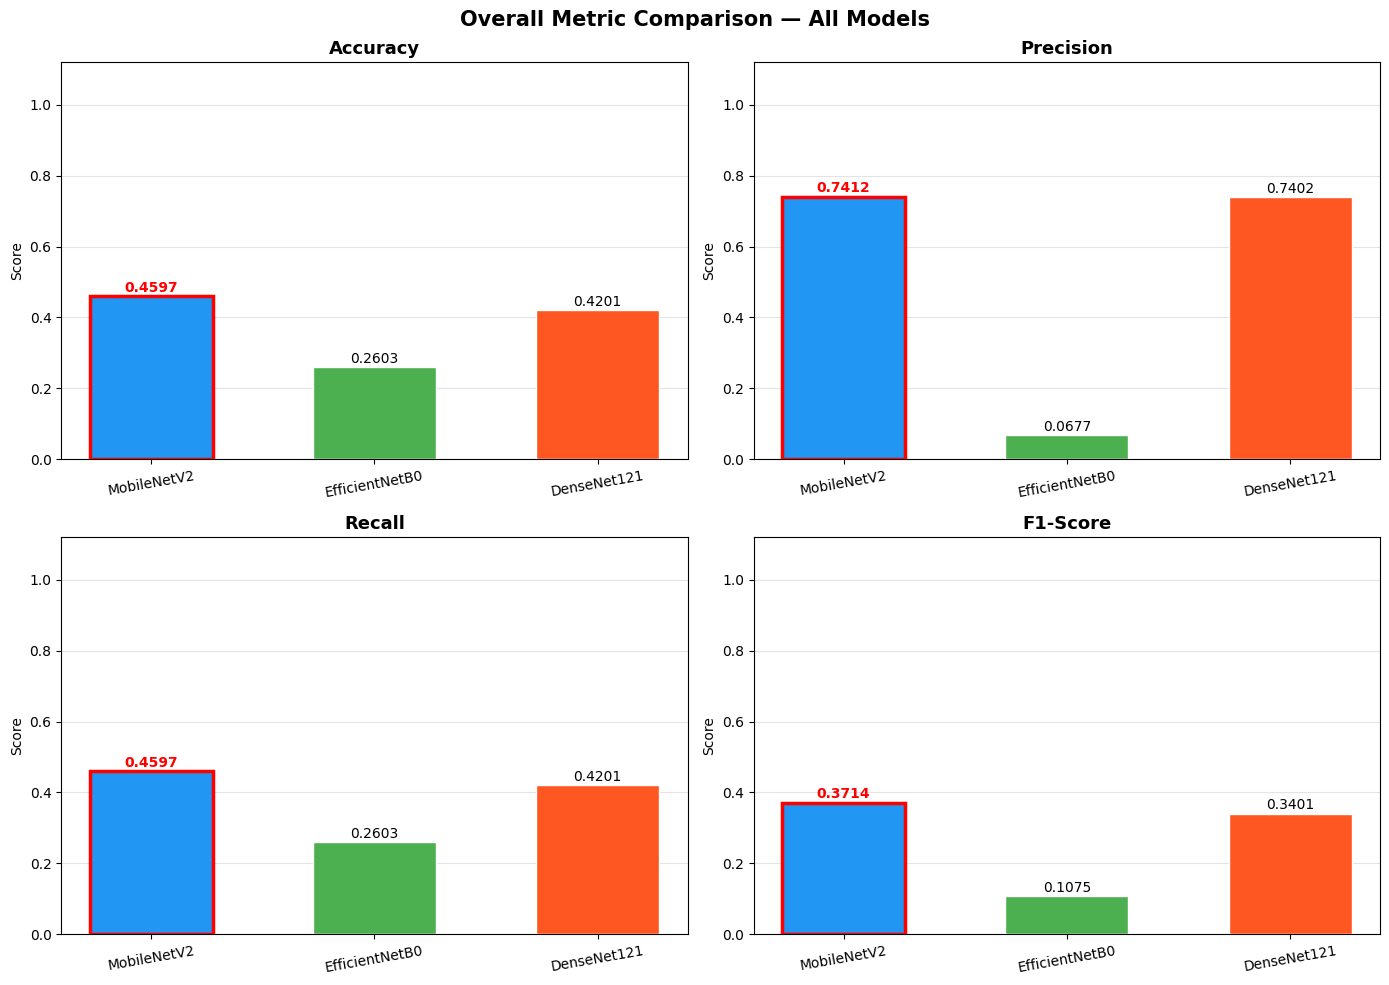

✅ Figure 8 saved.


In [ ]:
metrics     = ["accuracy", "precision", "recall", "f1_score"]
metric_lbls = ["Accuracy", "Precision", "Recall", "F1-Score"]
model_names = [r["name"] for r in results]
values_mat  = np.array([[r[m] for m in metrics] for r in results])

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Overall Metric Comparison — All Models",
             fontsize=15, fontweight="bold")

for ax, metric, label, idx in zip(axes.flat, metrics, metric_lbls, range(4)):
    vals   = values_mat[:, idx]
    colors = list(PALETTE.values())
    bars   = ax.bar(model_names, vals, color=colors,
                    edgecolor="white", width=0.55, zorder=3)
    ax.set_title(label, fontsize=13, fontweight="bold")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1.12)
    ax.grid(axis="y", alpha=0.35, zorder=0)
    ax.tick_params(axis="x", rotation=10)

    best_idx = int(np.argmax(vals))
    for i, (bar, val) in enumerate(zip(bars, vals)):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.012,
                f"{val:.4f}", ha="center", fontsize=10,
                fontweight="bold" if i == best_idx else "normal",
                color="red" if i == best_idx else "black")
    bars[best_idx].set_edgecolor("red")
    bars[best_idx].set_linewidth(2.5)

plt.tight_layout()
plt.savefig("/content/08_metrics_bar.png", dpi=120, bbox_inches="tight")
plt.show()
print("✅ Figure 8 saved.")

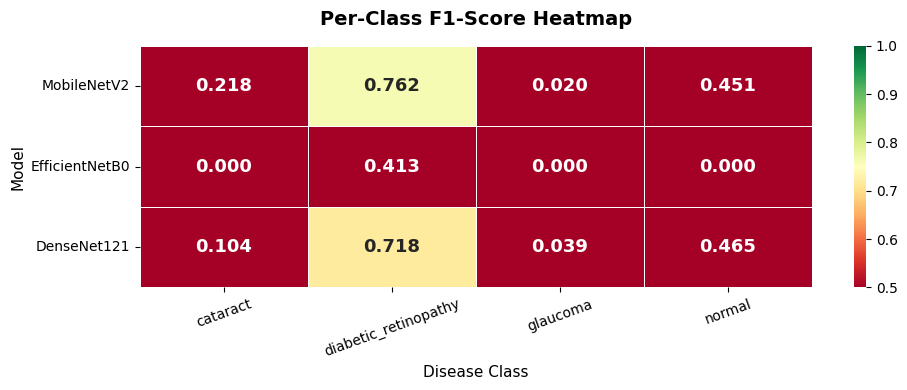

✅ Figure 9 saved.


In [ ]:
per_f1 = []
for res in results:
    row = [res["per_class"].get(cls, {}).get("f1-score", 0)
           for cls in CLASS_NAMES]
    per_f1.append(row)

per_f1_df = pd.DataFrame(per_f1, index=model_names, columns=CLASS_NAMES)

fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(per_f1_df, annot=True, fmt=".3f", cmap="RdYlGn",
            vmin=0.5, vmax=1.0, linewidths=0.5, linecolor="white",
            ax=ax, annot_kws={"size": 13, "weight": "bold"})
ax.set_title("Per-Class F1-Score Heatmap",
             fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Disease Class", fontsize=11)
ax.set_ylabel("Model", fontsize=11)
ax.tick_params(axis="x", rotation=20)
ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.savefig("/content/09_per_class_f1_heatmap.png", dpi=120, bbox_inches="tight")
plt.show()
print("✅ Figure 9 saved.")

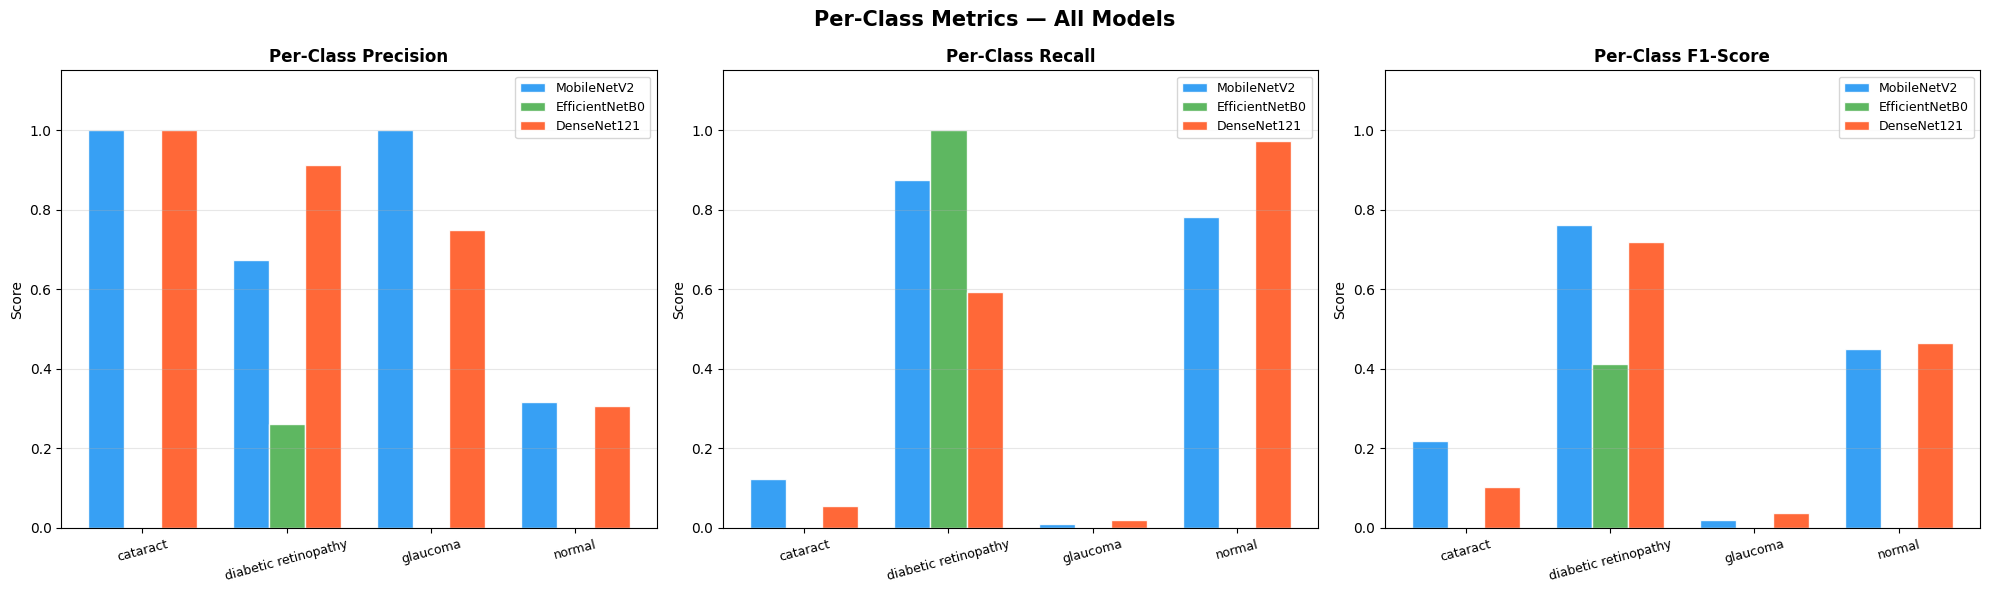

✅ Figure 10 saved.


In [ ]:
per_prec_mat = [[r["per_class"].get(c,{}).get("precision",0) for c in CLASS_NAMES] for r in results]
per_rec_mat  = [[r["per_class"].get(c,{}).get("recall",0)    for c in CLASS_NAMES] for r in results]
per_f1_mat   = [[r["per_class"].get(c,{}).get("f1-score",0)  for c in CLASS_NAMES] for r in results]

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle("Per-Class Metrics — All Models",
             fontsize=15, fontweight="bold")

x     = np.arange(len(CLASS_NAMES))
width = 0.25

for ax, mat, title in zip(axes,
    [per_prec_mat, per_rec_mat, per_f1_mat],
    ["Per-Class Precision", "Per-Class Recall", "Per-Class F1-Score"]):
    for i, (res, mat_row) in enumerate(zip(results, mat)):
        ax.bar(x + i*width, mat_row, width,
               label=res["name"], color=list(PALETTE.values())[i],
               edgecolor="white", alpha=0.9)
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xticks(x + width)
    ax.set_xticklabels([c.replace("_"," ") for c in CLASS_NAMES],
                        rotation=15, fontsize=9)
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1.15)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig("/content/10_per_class_metrics.png", dpi=120, bbox_inches="tight")
plt.show()
print("✅ Figure 10 saved.")


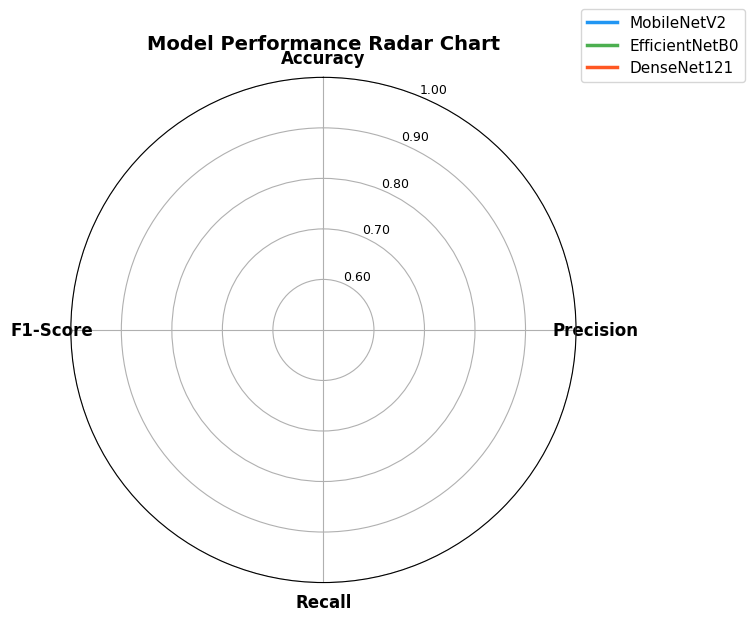

✅ Figure 11 saved.


In [ ]:
metric_labels = ["Accuracy", "Precision", "Recall", "F1-Score"]
N      = len(metric_labels)
angles = [n / float(N) * 2 * np.pi for n in range(N)] + \
         [0 / float(N) * 2 * np.pi]  # close polygon

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"polar": True})
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(metric_labels, size=12, fontweight="bold")
ax.set_ylim(0.5, 1.0)
ax.set_yticks([0.6, 0.7, 0.8, 0.9, 1.0])
ax.set_yticklabels(["0.60","0.70","0.80","0.90","1.00"], size=9)

for res, color in zip(results, PALETTE.values()):
    vals = [res[m] for m in ["accuracy","precision","recall","f1_score"]]
    vals += vals[:1]
    ax.plot(angles, vals, color=color, linewidth=2.5, label=res["name"])
    ax.fill(angles, vals, color=color, alpha=0.12)

ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.15), fontsize=11)
ax.set_title("Model Performance Radar Chart",
             fontsize=14, fontweight="bold", pad=20)
plt.tight_layout()
plt.savefig("/content/11_radar_chart.png", dpi=120, bbox_inches="tight")
plt.show()
print("✅ Figure 11 saved.")

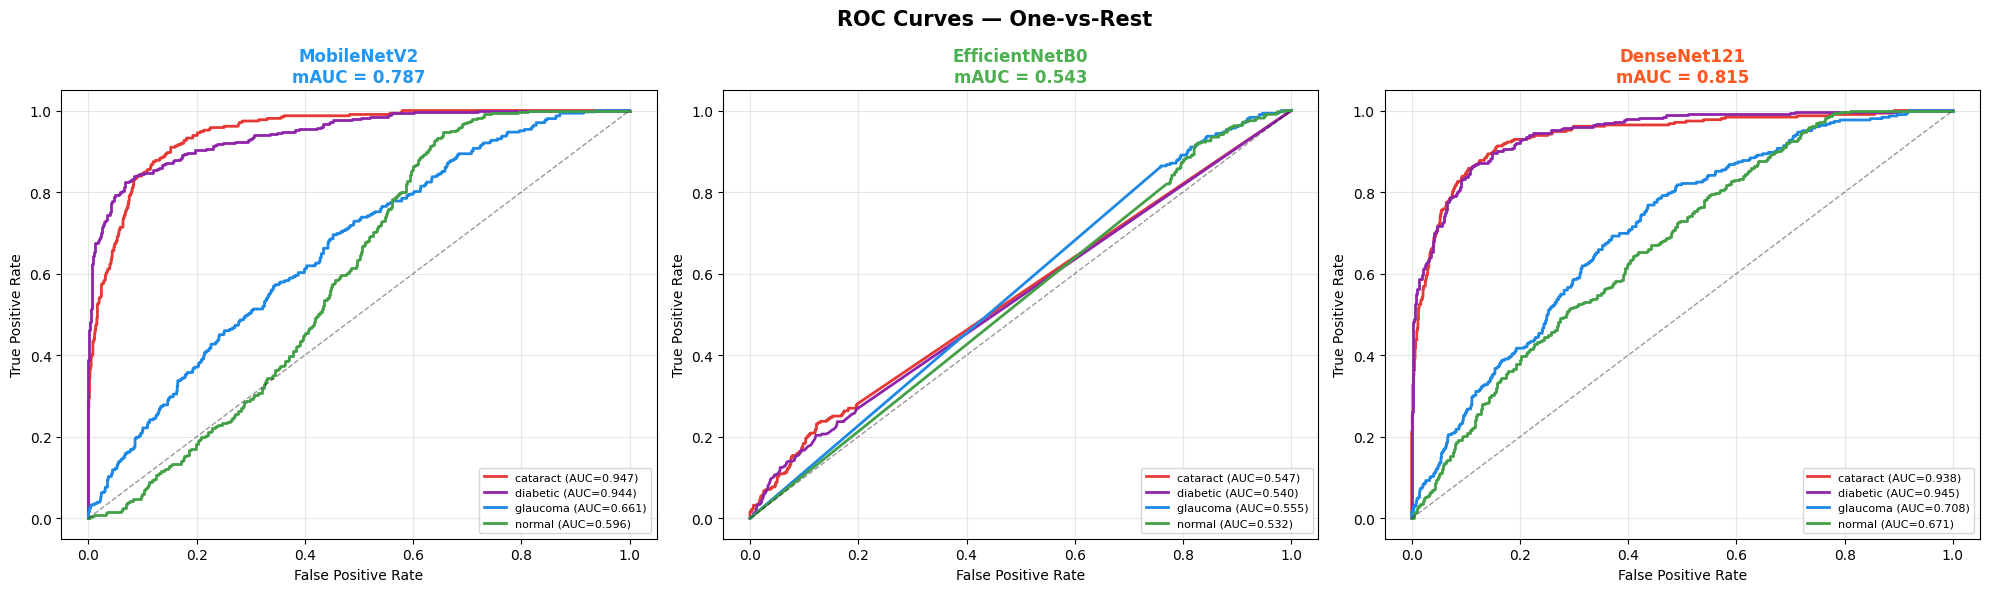

✅ Figure 12 saved.


In [ ]:
y_bin = label_binarize(val_data.classes[:val_data.samples],
                       classes=range(NUM_CLASSES))

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle("ROC Curves — One-vs-Rest",
             fontsize=15, fontweight="bold")

for ax, res, model_color in zip(axes, results, PALETTE.values()):
    y_score = res["y_score"][:len(y_bin)]
    aucs = []
    for i, cls in enumerate(CLASS_NAMES):
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_score[:, i])
        roc_auc     = auc(fpr, tpr)
        aucs.append(roc_auc)
        ax.plot(fpr, tpr, linewidth=2,
                label=f"{cls[:8]} (AUC={roc_auc:.3f})",
                color=CLASS_COLORS[i])
    ax.plot([0,1],[0,1], "k--", alpha=0.4, linewidth=1)
    ax.set_title(f"{res['name']}\nmAUC = {np.mean(aucs):.3f}",
                 fontsize=12, fontweight="bold", color=model_color)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend(fontsize=8, loc="lower right")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("/content/12_roc_curves.png", dpi=120, bbox_inches="tight")
plt.show()
print("✅ Figure 12 saved.")

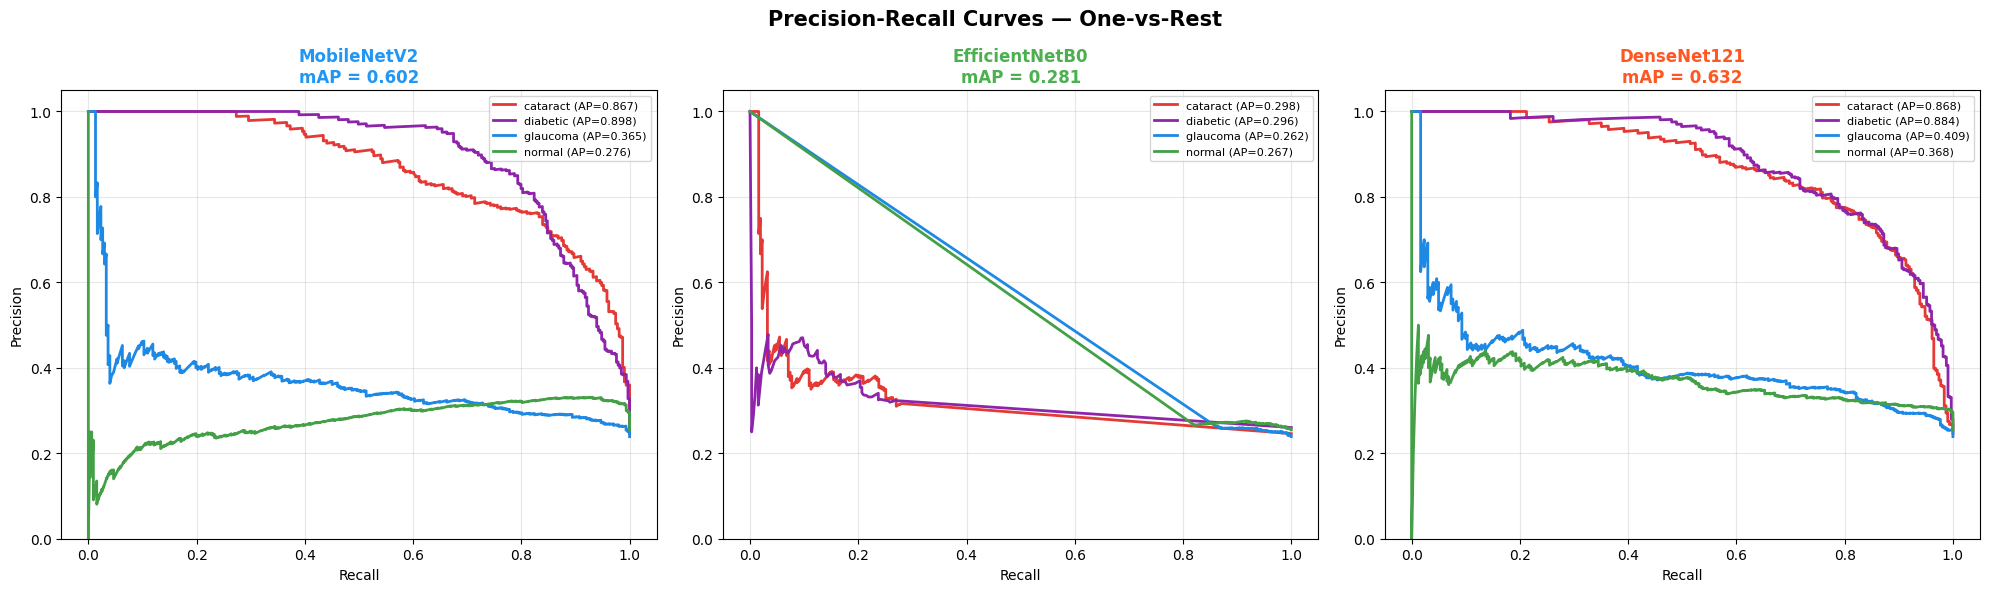

✅ Figure 13 saved.


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle("Precision-Recall Curves — One-vs-Rest",
             fontsize=15, fontweight="bold")

for ax, res, model_color in zip(axes, results, PALETTE.values()):
    y_score = res["y_score"][:len(y_bin)]
    aps = []
    for i, cls in enumerate(CLASS_NAMES):
        prec_c, rec_c, _ = precision_recall_curve(y_bin[:, i], y_score[:, i])
        ap = average_precision_score(y_bin[:, i], y_score[:, i])
        aps.append(ap)
        ax.plot(rec_c, prec_c, linewidth=2,
                label=f"{cls[:8]} (AP={ap:.3f})",
                color=CLASS_COLORS[i])
    ax.set_title(f"{res['name']}\nmAP = {np.mean(aps):.3f}",
                 fontsize=12, fontweight="bold", color=model_color)
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.set_ylim([0, 1.05])

plt.tight_layout()
plt.savefig("/content/13_pr_curves.png", dpi=120, bbox_inches="tight")
plt.show()
print("✅ Figure 13 saved.")


   FINAL RESULTS SUMMARY
         Model  Accuracy  Precision  Recall  F1-Score
   MobileNetV2    0.4597     0.7412  0.4597    0.3714
EfficientNetB0    0.2603     0.0677  0.2603    0.1075
   DenseNet121    0.4201     0.7402  0.4201    0.3401


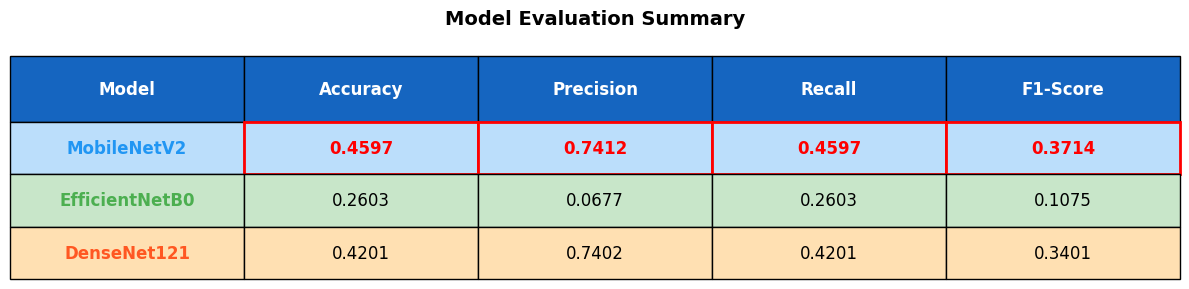

✅ Figure 14 saved.


In [ ]:
summary_df = pd.DataFrame([{
    "Model":     r["name"],
    "Accuracy":  round(r["accuracy"],  4),
    "Precision": round(r["precision"], 4),
    "Recall":    round(r["recall"],    4),
    "F1-Score":  round(r["f1_score"],  4),
} for r in results])

print("\n" + "="*60)
print("   FINAL RESULTS SUMMARY")
print("="*60)
print(summary_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(12, 3))
ax.axis("off")
col_labels = ["Model", "Accuracy", "Precision", "Recall", "F1-Score"]
row_data   = summary_df.values.tolist()
tbl = ax.table(cellText=row_data, colLabels=col_labels,
               cellLoc="center", loc="center", bbox=[0,0,1,1])
tbl.auto_set_font_size(False)
tbl.set_fontsize(12)

for j in range(len(col_labels)):
    tbl[0, j].set_facecolor("#1565C0")
    tbl[0, j].set_text_props(color="white", fontweight="bold")
    tbl[0, j].set_height(0.35)

row_colors = ["#BBDEFB", "#C8E6C9", "#FFE0B2"]
for i in range(len(results)):
    for j in range(len(col_labels)):
        tbl[i+1, j].set_facecolor(row_colors[i])
        tbl[i+1, j].set_height(0.28)
        if j == 0:
            tbl[i+1, j].set_text_props(
                fontweight="bold",
                color=list(PALETTE.values())[i]
            )

for mc, mname in enumerate(["Accuracy","Precision","Recall","F1-Score"]):
    best_row = summary_df[mname].idxmax()
    cell = tbl[best_row+1, mc+1]
    cell.set_text_props(fontweight="bold", color="red")
    cell.set_edgecolor("red")
    cell.set_linewidth(2)

ax.set_title("Model Evaluation Summary",
             fontsize=14, fontweight="bold", pad=20, y=1.02)
plt.tight_layout()
plt.savefig("/content/14_summary_table.png", dpi=120, bbox_inches="tight")
plt.show()
print("✅ Figure 14 saved.")

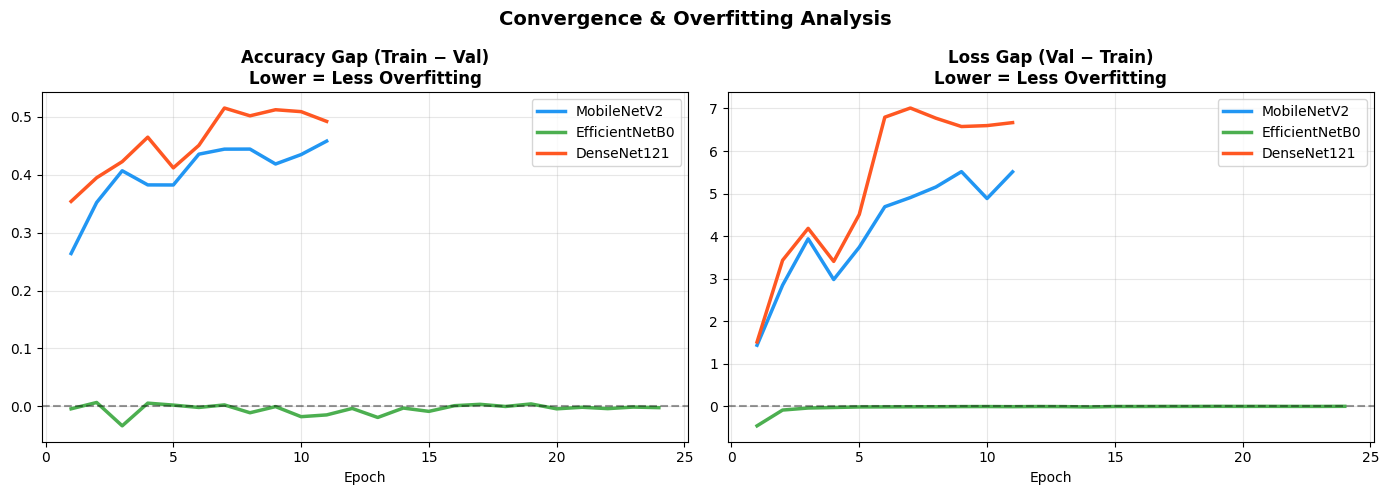

✅ Figure 15 saved.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Convergence & Overfitting Analysis",
             fontsize=14, fontweight="bold")

ep_counts = []
for name, hist in histories.items():
    color    = PALETTE[name]
    ep       = range(1, len(hist.history["accuracy"]) + 1)
    acc_gap  = np.array(hist.history["accuracy"]) - \
               np.array(hist.history["val_accuracy"])
    loss_gap = np.array(hist.history["val_loss"]) - \
               np.array(hist.history["loss"])
    axes[0].plot(ep, acc_gap,  color=color, linewidth=2.5, label=name)
    axes[1].plot(ep, loss_gap, color=color, linewidth=2.5, label=name)
    ep_counts.append(len(hist.history["val_accuracy"]))

for ax, title in [
    (axes[0], "Accuracy Gap (Train − Val)\nLower = Less Overfitting"),
    (axes[1], "Loss Gap (Val − Train)\nLower = Less Overfitting"),
]:
    ax.axhline(0, color="black", linestyle="--", alpha=0.4)
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("/content/15_overfitting_gap.png", dpi=120, bbox_inches="tight")
plt.show()
print("✅ Figure 15 saved.")

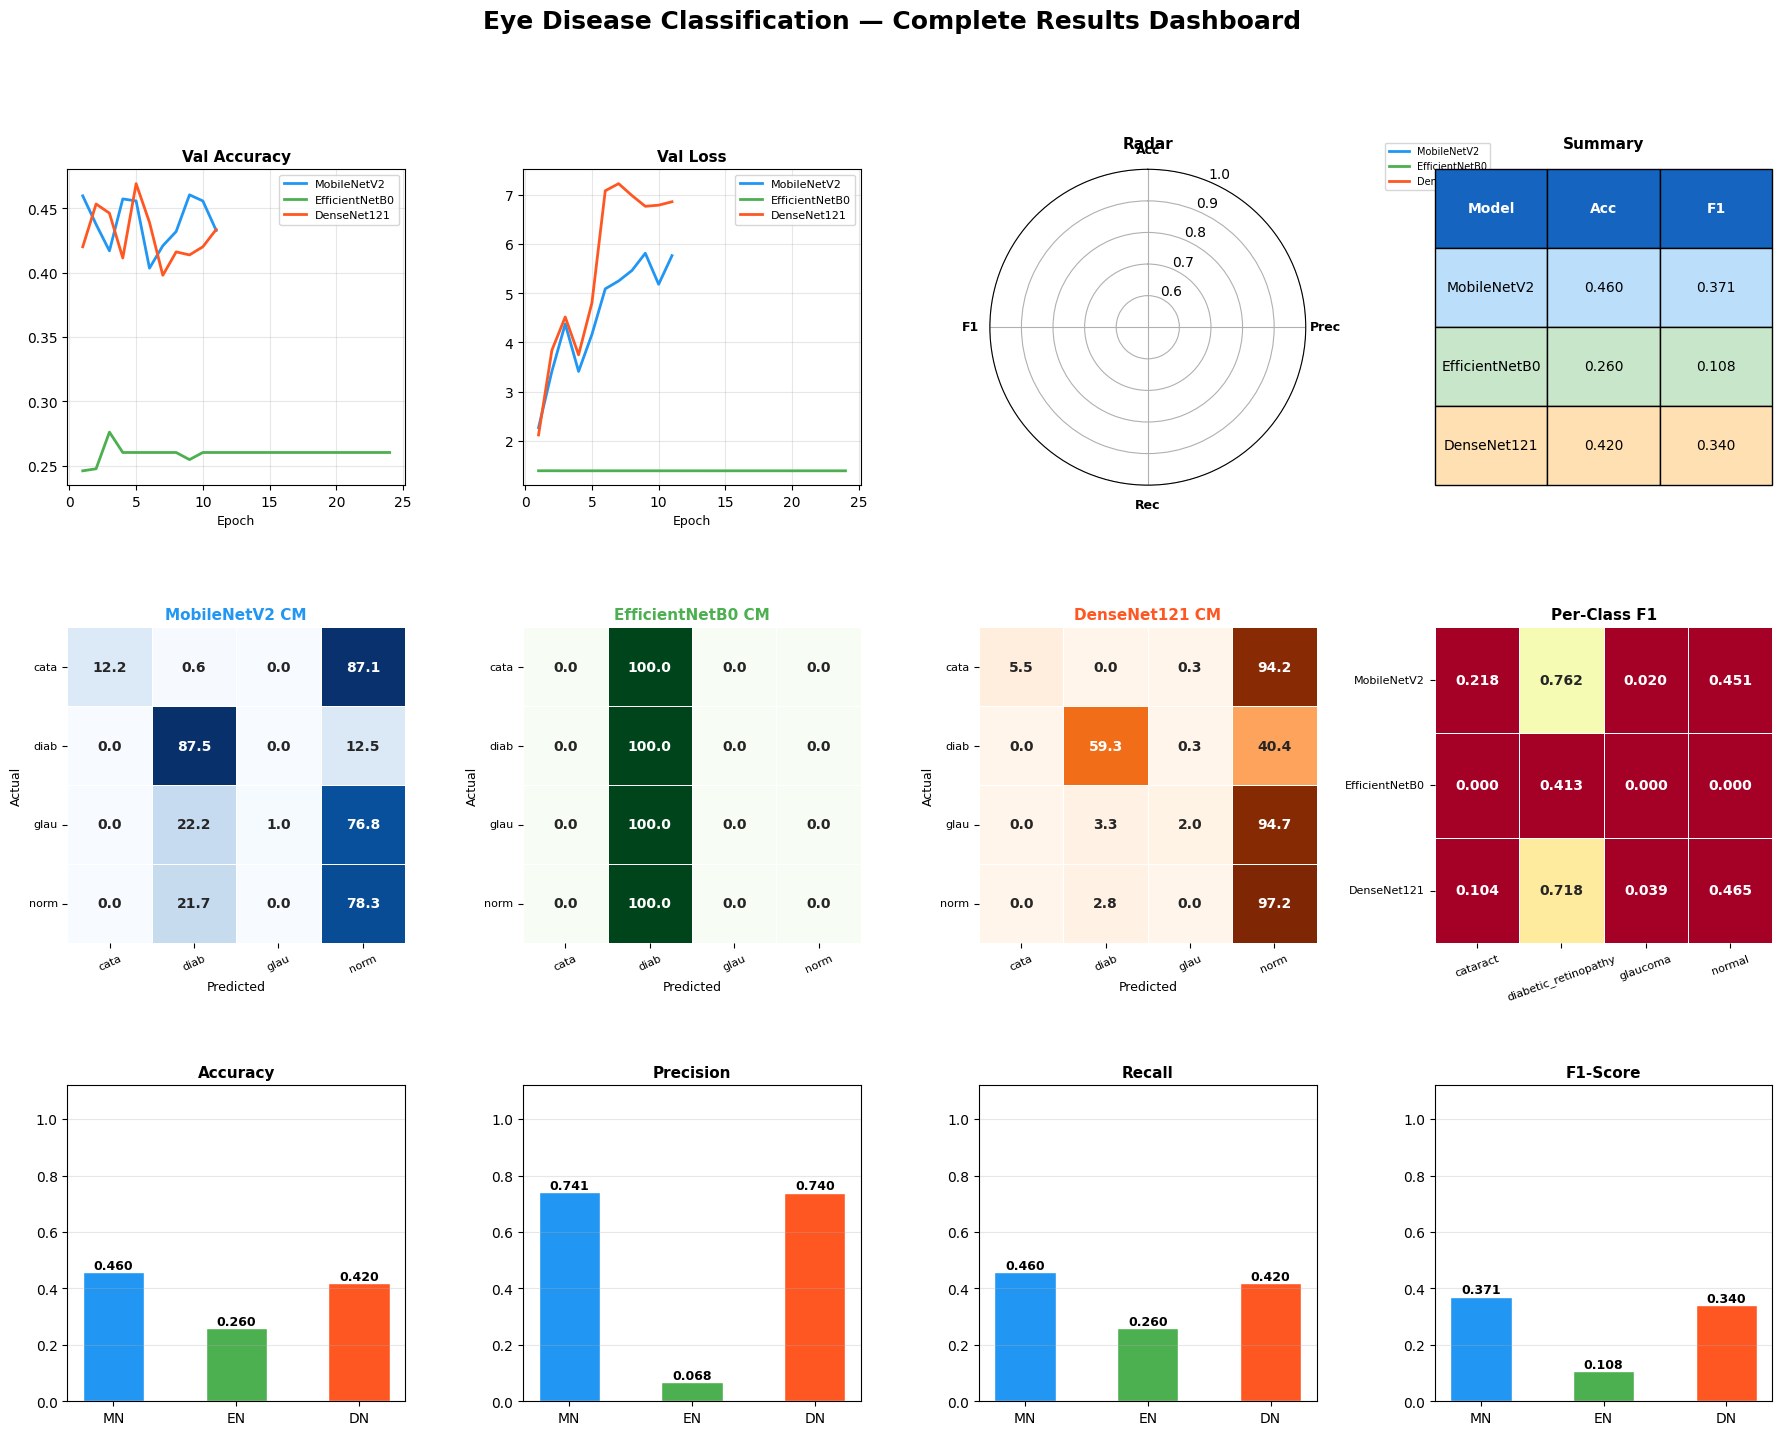

✅ DASHBOARD saved: 00_DASHBOARD.png


In [ ]:
fig = plt.figure(figsize=(22, 16))
fig.suptitle("Eye Disease Classification — Complete Results Dashboard",
             fontsize=18, fontweight="bold", y=0.98)
gs = gridspec.GridSpec(3, 4, figure=fig, hspace=0.45, wspace=0.35)

# Row 1: val accuracy | val loss | radar | summary
ax_acc  = fig.add_subplot(gs[0, 0])
ax_loss = fig.add_subplot(gs[0, 1])
ax_rad  = fig.add_subplot(gs[0, 2], polar=True)
ax_tbl  = fig.add_subplot(gs[0, 3])

for name, hist in histories.items():
    color = PALETTE[name]
    ep    = range(1, len(hist.history["val_accuracy"]) + 1)
    ax_acc.plot(ep, hist.history["val_accuracy"],
                color=color, linewidth=2, label=name)
    ax_loss.plot(ep, hist.history["val_loss"],
                 color=color, linewidth=2, label=name)

for ax, title, ylabel in [
    (ax_acc,  "Val Accuracy", "Accuracy"),
    (ax_loss, "Val Loss",     "Loss"),
]:
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel("Epoch", fontsize=9)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

# Radar
ax_rad.set_theta_offset(np.pi / 2)
ax_rad.set_theta_direction(-1)
ax_rad.set_xticks(angles[:-1])
ax_rad.set_xticklabels(["Acc","Prec","Rec","F1"], size=9, fontweight="bold")
ax_rad.set_ylim(0.5, 1.0)
for res, color in zip(results, PALETTE.values()):
    vals = [res[m] for m in ["accuracy","precision","recall","f1_score"]] + \
           [res["accuracy"]]
    ax_rad.plot(angles, vals, color=color, linewidth=2, label=res["name"])
    ax_rad.fill(angles, vals, color=color, alpha=0.1)
ax_rad.set_title("Radar", fontsize=11, fontweight="bold", pad=15)
ax_rad.legend(fontsize=7, loc="upper right", bbox_to_anchor=(1.6, 1.1))

# Mini table
ax_tbl.axis("off")
tdata = [[r["name"], f"{r['accuracy']:.3f}", f"{r['f1_score']:.3f}"]
         for r in results]
mt = ax_tbl.table(cellText=tdata, colLabels=["Model","Acc","F1"],
                  cellLoc="center", loc="center", bbox=[0,0,1,1])
mt.auto_set_font_size(False)
mt.set_fontsize(10)
for j in range(3):
    mt[0,j].set_facecolor("#1565C0")
    mt[0,j].set_text_props(color="white", fontweight="bold")
rc = ["#BBDEFB","#C8E6C9","#FFE0B2"]
for i in range(3):
    for j in range(3):
        mt[i+1,j].set_facecolor(rc[i])
ax_tbl.set_title("Summary", fontsize=11, fontweight="bold", pad=15)

# Row 2: confusion matrices + per-class F1 heatmap
for col, (res, cmap) in enumerate(zip(results, ["Blues","Greens","Oranges"])):
    ax = fig.add_subplot(gs[1, col])
    cm_pct = res["cm"].astype(float) / res["cm"].sum(axis=1, keepdims=True) * 100
    sns.heatmap(cm_pct, annot=True, fmt=".1f", cmap=cmap, ax=ax,
                xticklabels=[c[:4] for c in CLASS_NAMES],
                yticklabels=[c[:4] for c in CLASS_NAMES],
                cbar=False, linewidths=0.5, linecolor="white",
                annot_kws={"size":10,"weight":"bold"})
    ax.set_title(f"{res['name']} CM",
                 fontsize=11, fontweight="bold",
                 color=list(PALETTE.values())[col])
    ax.set_xlabel("Predicted", fontsize=9)
    ax.set_ylabel("Actual", fontsize=9)
    ax.tick_params(axis="x", rotation=25, labelsize=8)
    ax.tick_params(axis="y", rotation=0, labelsize=8)

ax_pc = fig.add_subplot(gs[1, 3])
sns.heatmap(per_f1_df, annot=True, fmt=".3f", cmap="RdYlGn",
            vmin=0.5, vmax=1.0, ax=ax_pc, cbar=False,
            linewidths=0.5, linecolor="white",
            annot_kws={"size":10,"weight":"bold"})
ax_pc.set_title("Per-Class F1", fontsize=11, fontweight="bold")
ax_pc.tick_params(axis="x", rotation=20, labelsize=8)
ax_pc.tick_params(axis="y", rotation=0, labelsize=8)

# Row 3: metric bars
for col, (metric, label) in enumerate(zip(
    ["accuracy","precision","recall","f1_score"],
    ["Accuracy","Precision","Recall","F1-Score"]
)):
    ax = fig.add_subplot(gs[2, col])
    vals   = [r[metric] for r in results]
    colors = list(PALETTE.values())
    bars   = ax.bar(["MN","EN","DN"], vals, color=colors,
                    edgecolor="white", width=0.5)
    ax.set_title(label, fontsize=11, fontweight="bold")
    ax.set_ylim(0, 1.12)
    ax.grid(axis="y", alpha=0.3)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.01,
                f"{val:.3f}", ha="center",
                fontsize=9, fontweight="bold")

plt.savefig("/content/00_DASHBOARD.png", dpi=130, bbox_inches="tight")
plt.show()
print("✅ DASHBOARD saved: 00_DASHBOARD.png")


In [ ]:
print("\n" + "="*60)
print("   EYE DISEASE CLASSIFICATION — FINAL SUMMARY")
print("="*60)
print(f"\n  Dataset : Eye Diseases Classification (Kaggle)")
print(f"  Classes : {CLASS_NAMES}")
print(f"  Train   : {train_data.samples} | Val: {val_data.samples}")
print(f"  IMG     : {IMG_SIZE}×{IMG_SIZE} | Batch: {BATCH_SIZE}")
print(f"\n{'─'*60}")
print(f"  {'Model':<18} {'Acc':>8} {'Prec':>8} {'Rec':>8} {'F1':>8}")
print(f"{'─'*60}")
for r in results:
    best = "⭐" if r["f1_score"] == max(x["f1_score"] for x in results) else "  "
    print(f"  {best}{r['name']:<16} {r['accuracy']:>8.4f} "
          f"{r['precision']:>8.4f} {r['recall']:>8.4f} {r['f1_score']:>8.4f}")
print(f"{'─'*60}")
best = max(results, key=lambda x: x["f1_score"])
fast = min(results, key=lambda x: len(histories[x["name"]].history["val_accuracy"]))
print(f"\n  ⭐ Best Model     : {best['name']} (F1={best['f1_score']:.4f})")
print(f"  ⚡ Fastest Conv.  : {fast['name']} "
      f"({len(histories[fast['name']].history['val_accuracy'])} epochs)")
print(f"\n  All figures saved to /content/")
print("="*60)


   EYE DISEASE CLASSIFICATION — FINAL SUMMARY

  Dataset : Eye Diseases Classification (Kaggle)
  Classes : ['cataract', 'diabetic_retinopathy', 'glaucoma', 'normal']
  Train   : 2953 | Val: 1264
  IMG     : 224×224 | Batch: 16

────────────────────────────────────────────────────────────
  Model                   Acc     Prec      Rec       F1
────────────────────────────────────────────────────────────
  ⭐MobileNetV2        0.4597   0.7412   0.4597   0.3714
    EfficientNetB0     0.2603   0.0677   0.2603   0.1075
    DenseNet121        0.4201   0.7402   0.4201   0.3401
────────────────────────────────────────────────────────────

  ⭐ Best Model     : MobileNetV2 (F1=0.3714)
  ⚡ Fastest Conv.  : MobileNetV2 (11 epochs)

  All figures saved to /content/


In [ ]:
import glob, zipfile
from google.colab import files

output_zip  = "/content/eye_disease_results.zip"
plot_files  = sorted(glob.glob("/content/*.png"))
model_files = glob.glob("/content/*.h5")

with zipfile.ZipFile(output_zip, "w") as zf:
    for f in plot_files + model_files:
        zf.write(f, os.path.basename(f))

print(f"✅ ZIP created: {output_zip}")
print(f"   {len(plot_files)} plots + {len(model_files)} model files")
files.download(output_zip)
print("✅ Download started!")

✅ ZIP created: /content/eye_disease_results.zip
   20 plots + 3 model files


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Download started!
